In [ ]:
import json
import os

import numpy as np

folder = "trizod-2025_12_12"
filtering = "tolerant"
# created with trizod https://github.com/invemichele-peptone/trizod/tree/52b4020af8ff3c5e114c31eb31742ed484994451
data = {}
with open(f"{folder}/{filtering}.json") as f:
    for line in f:
        d = json.loads(line)
        data[d["ID"]] = {
            prop: d[prop]
            for prop in ["seq", "entity_name", "temperature", "pH", "ionic_strength", "total_bbshifts", "gscores"]
        }
        data[d["ID"]]["gscores"] = np.array(data[d["ID"]]["gscores"], dtype=float)

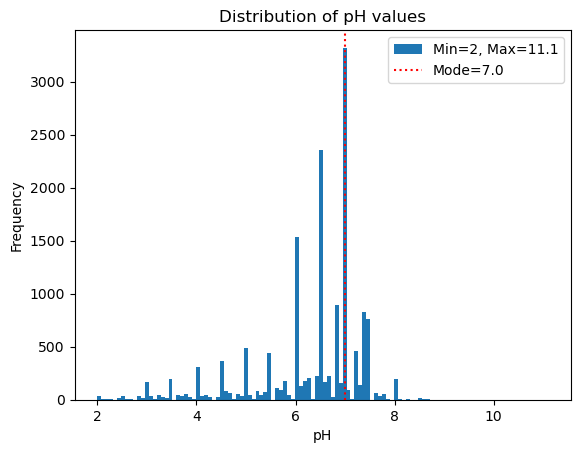

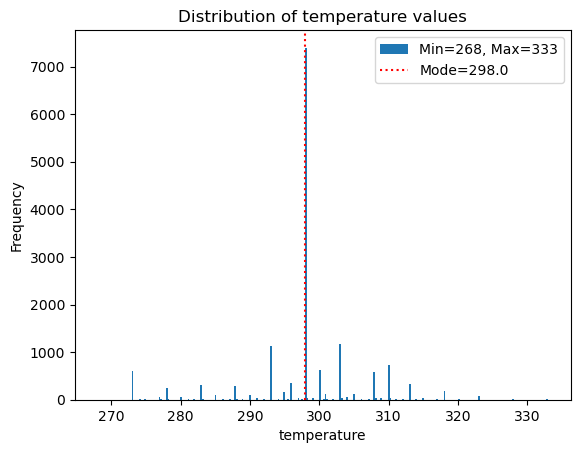

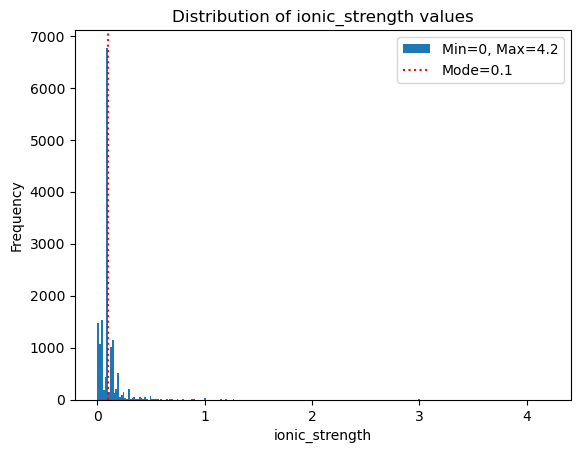

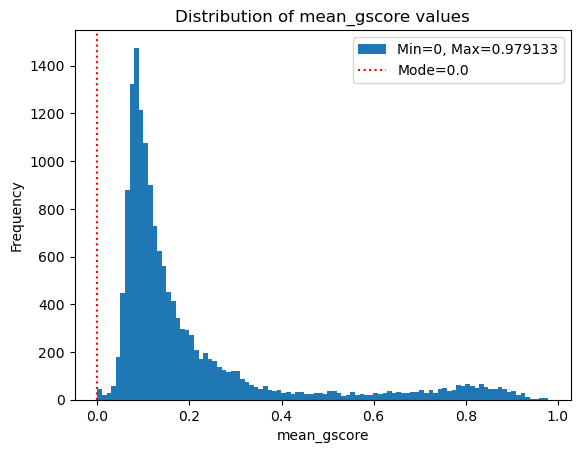

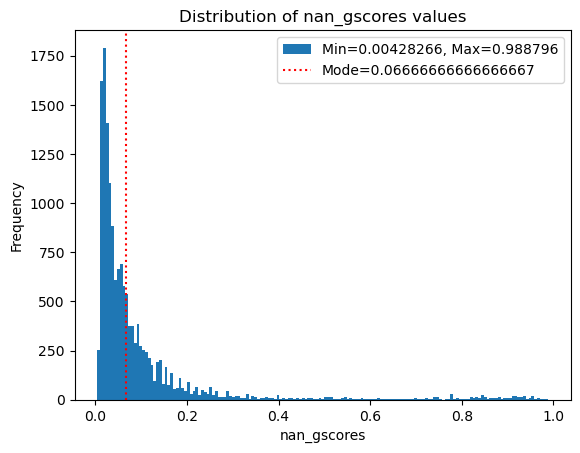

In [30]:
import matplotlib.pyplot as plt
from scipy import stats

all_pH_values = np.array([d["pH"] for d in data.values()], dtype=float)
all_temperature_values = np.array([d["temperature"] for d in data.values()], dtype=float)
all_ionic_strength_values = np.array([d["ionic_strength"] for d in data.values()], dtype=float)
props = {"pH": all_pH_values, "temperature": all_temperature_values, "ionic_strength": all_ionic_strength_values}
props["mean_gscore"] = np.array([np.nanmean(d["gscores"]) for d in data.values()], dtype=float)
props["nan_gscores"] = np.array([sum(np.isnan(d["gscores"])) / len(d["gscores"]) for d in data.values()], dtype=float)

for prop, val in props.items():
    plt.hist(val, bins="auto", label=f"Min={val.min():g}, Max={val.max():g}")
    plt.axvline(stats.mode(val).mode, c="r", ls=":", label=f"Mode={stats.mode(val).mode}")
    plt.title(f"Distribution of {prop} values")
    plt.xlabel(prop)
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()


In [31]:
# cluster with mmseqs2
nan_threshold = 0.5
print(f"Filtering out sequences with more than {nan_threshold} NaN gscores")
print(f"  removing {sum(np.isnan(d['gscores']).sum() / len(d['gscores']) >= nan_threshold for d in data.values()):_} out of {len(data):_} sequences")
print()

if not os.path.exists(f"{folder}/{filtering}_cluster.tsv"):
    with open(f"{folder}/{filtering}.fasta", "w") as f:
        for label, d in data.items():
            if np.isnan(d["gscores"]).sum() / len(d["gscores"]) < nan_threshold:
                f.write(f">{label}\n{d['seq']}\n")
    import subprocess

    docker_cmd = [
        "docker", "run", "--rm",
        "--user", f"{os.getuid()}:{os.getgid()}",
        "-v", f"{os.path.abspath(folder)}:/data",
        "-w", "/data",
        "ghcr.io/soedinglab/mmseqs2",
        "easy-cluster",
        f"{filtering}.fasta",
        f"{filtering}",
        "/tmp"
    ]
    subprocess.run(docker_cmd, check=True)
    os.remove(f"{folder}/{filtering}.fasta")

Filtering out sequences with more than 0.5 NaN gscores
  removing 617 out of 15_543 sequences

easy-cluster tolerant.fasta tolerant /tmp 

MMseqs Version:                     	8cc5ce367b5638c4306c2d7cfc652dd099a4643f
Substitution matrix                 	aa:blosum62.out,nucl:nucleotide.out
Seed substitution matrix            	aa:VTML80.out,nucl:nucleotide.out
Sensitivity                         	4
k-mer length                        	0
Target search mode                  	0
k-score                             	seq:2147483647,prof:2147483647
Alphabet size                       	aa:21,nucl:5
Max sequence length                 	65535
Max results per query               	20
Split database                      	0
Split mode                          	2
Split memory limit                  	0
Coverage threshold                  	0.8
Coverage mode                       	0
Compositional bias                  	1
Compositional bias scale            	1
Diagonal scoring                    	true
Exac

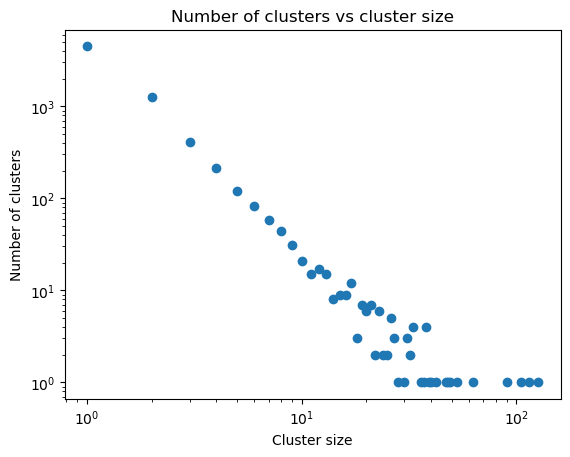

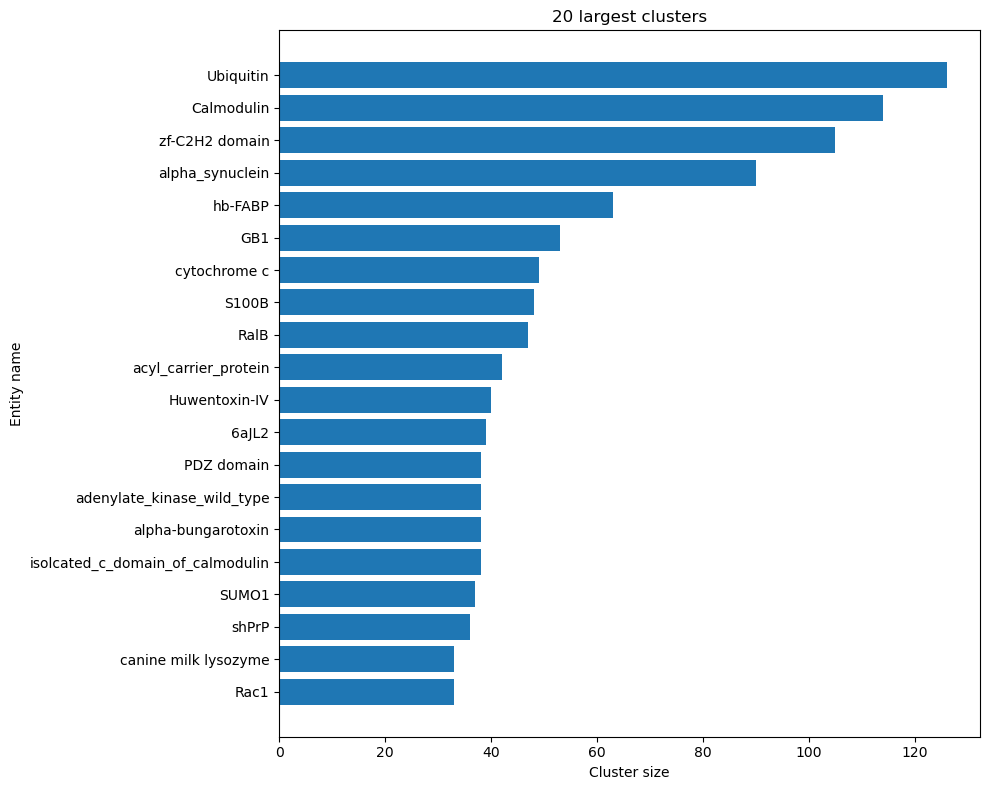

,representative,member,cluster_size,best_entity_name
0,27461_1_1_1,27461_1_1_1,1,TGIF1
1,15279_1_1_1,15279_1_1_1,1,EH domain of EHD1
2,17510_1_1_1,17510_1_1_1,1,Ssu72
3,25705_1_1_1,25705_1_1_1,1,Nucleoprotein
4,34202_1_1_1,34202_1_1_1,2,entity_1
...,...,...,...,...
14921,10088_1_1_1,16507_1_1_1,38,PDZ domain
14922,10088_1_1_1,6933_1_1_1,38,PDZ domain
14923,10088_1_1_1,11202_1_1_1,38,PDZ domain
14924,10088_1_1_1,6927_1_1_1,38,PDZ domain


In [32]:
from collections import Counter

import pandas as pd

clusters_df = pd.read_csv(f"{folder}/{filtering}_cluster.tsv", sep="\t", names=["representative", "member"])
cluster_sizes = clusters_df.groupby("representative").size()
clusters_df["cluster_size"] = clusters_df["representative"].map(cluster_sizes)

best_entity_name = {}
for rep in clusters_df["representative"].unique():
    entity_names = [
        data[id]["entity_name"].strip().replace("\n", " ")
        for id in clusters_df[clusters_df["representative"] == rep]["member"]
    ]
    meaningful_names = [n for n in entity_names if n and "entity" not in n.lower()]
    if meaningful_names:
        best_entity_name[rep] = Counter(meaningful_names).most_common(1)[0]
    elif entity_names:
        best_entity_name[rep] = Counter(entity_names).most_common(1)[0]
    else:
        best_entity_name[rep] = None
clusters_df["best_entity_name"] = clusters_df["representative"].map(lambda rep: best_entity_name[rep][0])

cluster_size_counts = cluster_sizes.value_counts().sort_index()
plt.scatter(cluster_size_counts.index, cluster_size_counts.values)
plt.title("Number of clusters vs cluster size")
plt.xlabel("Cluster size")
plt.ylabel("Number of clusters")
plt.yscale("log")
plt.xscale("log")
plt.show()

# show a bar plot of the size of the n_top largest clusters, with the entity names on the y-axis
n_top = 20
top_n_clusters = cluster_sizes.nlargest(n_top).sort_values()
top_n_names = [best_entity_name.get(rep, (rep,))[0] or rep for rep in top_n_clusters.index]
plt.figure(figsize=(10, 8))
plt.barh(range(len(top_n_clusters)), top_n_clusters.values)
plt.yticks(range(len(top_n_clusters)), top_n_names)
plt.xlabel("Cluster size")
plt.ylabel("Entity name")
plt.title(f"{n_top} largest clusters")
plt.tight_layout()
plt.show()

clusters_df

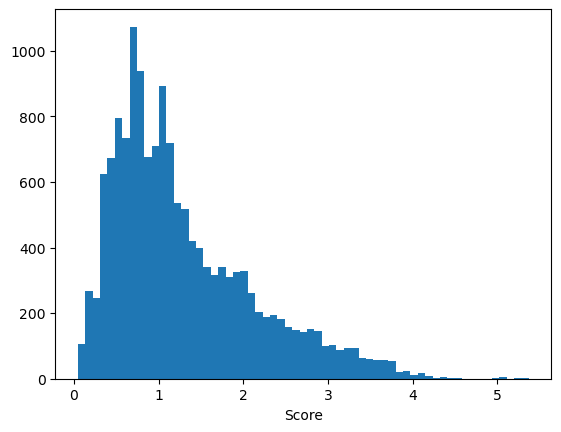

,representative,member,cluster_size,best_entity_name,score
0,27461_1_1_1,27461_1_1_1,1,TGIF1,1.592908
1,15279_1_1_1,15279_1_1_1,1,EH domain of EHD1,0.375101
2,17510_1_1_1,17510_1_1_1,1,Ssu72,1.840278
3,25705_1_1_1,25705_1_1_1,1,Nucleoprotein,0.838409
4,34202_1_1_1,34202_1_1_1,2,entity_1,0.687726
...,...,...,...,...,...
14921,10088_1_1_1,16507_1_1_1,38,PDZ domain,1.023555
14922,10088_1_1_1,6933_1_1_1,38,PDZ domain,0.706975
14923,10088_1_1_1,11202_1_1_1,38,PDZ domain,1.073544
14924,10088_1_1_1,6927_1_1_1,38,PDZ domain,0.688727


In [33]:
def get_conditions_score(temperature: float, pH: float, ionic_strength: float, gscores: np.ndarray) -> float:
    delta_temperature = (temperature - 298.0) / 15.0
    delta_pH = (pH - 7.4) / 1.5
    delta_ionic_strength = (ionic_strength - 0.1) / 3
    return np.linalg.norm([delta_temperature, delta_pH, delta_ionic_strength]) + 5 * np.isnan(gscores).sum() / len(
        gscores,
    )


clusters_df["score"] = clusters_df.apply(
    lambda row: get_conditions_score(
        data[row["member"]]["temperature"],
        data[row["member"]]["pH"],
        data[row["member"]]["ionic_strength"],
        data[row["member"]]["gscores"],
    ),
    axis=1,
)
plt.hist(clusters_df["score"], bins="auto")
plt.xlabel("Score")
plt.show()

clusters_df

Found 355 different best representatives out of 6_888
Found 1_260 different new representatives out of 6_888


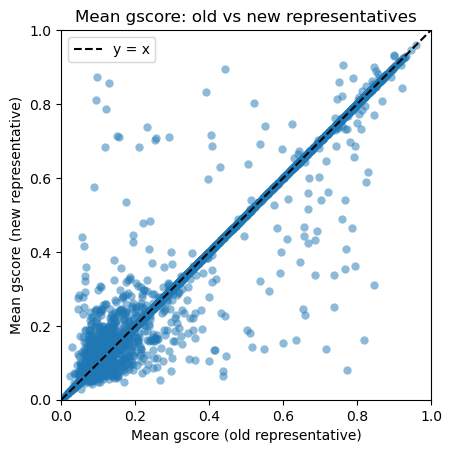

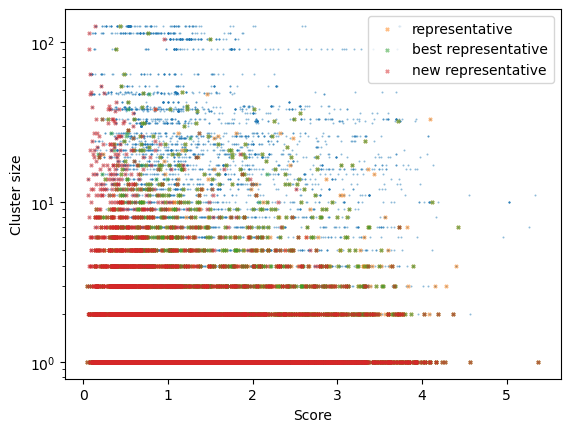

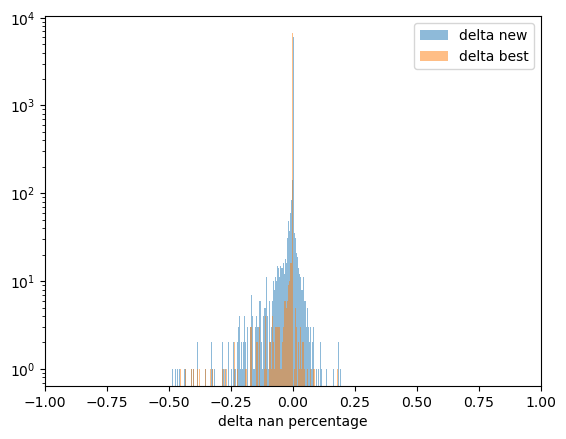

,representative,member,cluster_size,best_entity_name,score,new_representative,best_representative
0,27461_1_1_1,27461_1_1_1,1,TGIF1,1.592908,27461_1_1_1,27461_1_1_1
1,15279_1_1_1,15279_1_1_1,1,EH domain of EHD1,0.375101,15279_1_1_1,15279_1_1_1
2,17510_1_1_1,17510_1_1_1,1,Ssu72,1.840278,17510_1_1_1,17510_1_1_1
3,25705_1_1_1,25705_1_1_1,1,Nucleoprotein,0.838409,25705_1_1_1,25705_1_1_1
4,34202_1_1_1,34202_1_1_1,2,entity_1,0.687726,34216_1_1_1,34202_1_1_1
...,...,...,...,...,...,...,...
14921,10088_1_1_1,16507_1_1_1,38,PDZ domain,1.023555,16637_1_1_1,10088_1_1_1
14922,10088_1_1_1,6933_1_1_1,38,PDZ domain,0.706975,16637_1_1_1,10088_1_1_1
14923,10088_1_1_1,11202_1_1_1,38,PDZ domain,1.073544,16637_1_1_1,10088_1_1_1
14924,10088_1_1_1,6927_1_1_1,38,PDZ domain,0.688727,16637_1_1_1,10088_1_1_1


In [34]:
clusters_df["new_representative"] = clusters_df["representative"].map(
    clusters_df.loc[clusters_df.groupby("representative")["score"].idxmin()].set_index("representative")["member"],
)
clusters_df["best_representative"] = clusters_df["representative"].map(
    clusters_df[clusters_df.apply(lambda r: data[r["member"]]["seq"] == data[r["representative"]]["seq"], axis=1)]
    .groupby("representative")
    .apply(lambda g: g.nsmallest(1, "score")["member"].iloc[0], include_groups=False),
)
rep_pairs = clusters_df[["representative", "best_representative"]].drop_duplicates()
print(f"Found {sum(a != b for (a, b) in rep_pairs.values):_} different best representatives out of {len(rep_pairs):_}")

# Get unique pairs of (representative, new_representative)
rep_pairs = clusters_df[["representative", "new_representative"]].drop_duplicates()
print(f"Found {sum(a != b for (a, b) in rep_pairs.values):_} different new representatives out of {len(rep_pairs):_}")
old_mean_gscores = [np.nanmean(data[rep]["gscores"]) for rep in rep_pairs["representative"]]
new_mean_gscores = [np.nanmean(data[new_rep]["gscores"]) for new_rep in rep_pairs["new_representative"]]

plt.scatter(old_mean_gscores, new_mean_gscores, alpha=0.5, lw=0)
plt.plot([0, 1], [0, 1], "k--", label="y = x")
plt.xlabel("Mean gscore (old representative)")
plt.ylabel("Mean gscore (new representative)")
plt.title("Mean gscore: old vs new representatives")
plt.legend()
plt.gca().set_aspect("equal", adjustable="box")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

plt.scatter(clusters_df["score"], clusters_df["cluster_size"], alpha=0.5, lw=0, s=2)
plt.scatter(
    clusters_df[clusters_df["member"] == clusters_df["representative"]]["score"],
    clusters_df[clusters_df["member"] == clusters_df["representative"]]["cluster_size"],
    marker="x",
    alpha=0.5,
    s=5,
    label="representative",
)
plt.scatter(
    clusters_df[clusters_df["member"] == clusters_df["best_representative"]]["score"],
    clusters_df[clusters_df["member"] == clusters_df["best_representative"]]["cluster_size"],
    marker="x",
    alpha=0.5,
    s=5,
    label="best representative",
)
plt.scatter(
    clusters_df[clusters_df["member"] == clusters_df["new_representative"]]["score"],
    clusters_df[clusters_df["member"] == clusters_df["new_representative"]]["cluster_size"],
    marker="x",
    alpha=0.5,
    s=5,
    label="new representative",
)
plt.xlabel("Score")
plt.ylabel("Cluster size")
plt.yscale("log")
plt.legend()
plt.show()


# Compute deltas per cluster (new_rep - rep and best_rep - rep)
rep_pairs_all = clusters_df[["representative", "new_representative", "best_representative"]].drop_duplicates()
delta_new_vs_rep = np.array(
    [
        np.isnan(data[new_rep]["gscores"]).sum() / len(data[new_rep]["gscores"])
        - np.isnan(data[rep]["gscores"]).sum() / len(data[rep]["gscores"])
        for rep, new_rep, best_rep in rep_pairs_all.values
    ]
)
delta_best_vs_rep = np.array(
    [
        np.isnan(data[best_rep]["gscores"]).sum() / len(data[best_rep]["gscores"])
        - np.isnan(data[rep]["gscores"]).sum() / len(data[rep]["gscores"])
        for rep, new_rep, best_rep in rep_pairs_all.values
    ]
)

plt.hist(delta_new_vs_rep, bins="auto", alpha=0.5, label="delta new")
plt.hist(delta_best_vs_rep, bins="auto", alpha=0.5, label="delta best")
plt.yscale("log")
plt.legend()
plt.xlim(-1, 1)
plt.xlabel("delta nan percentage")
plt.show()

clusters_df

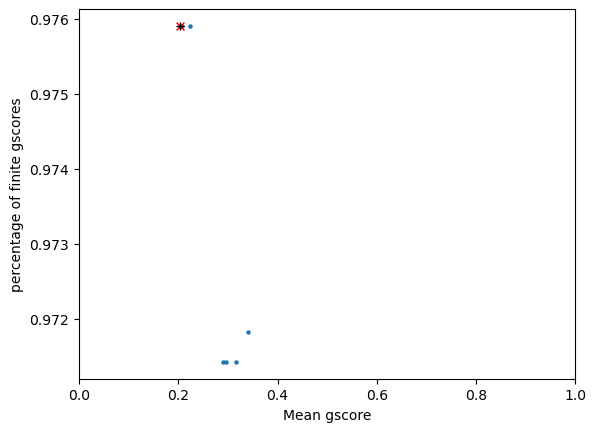

4069_1_1_1 2.3455911634813287 {'seq': 'MFPAMPLSSLFVNGPRTLCGAELVDALQFVCGDRGFYFNKPTGYGSSSRRAPQTGIVDECCFRSCDLRRLEMYCAPLKPAKSA', 'entity_name': 'Long-[Arg-3]-Insulin-Like Growth Factor-I', 'temperature': 303.0, 'pH': 4.1, 'ionic_strength': 0.1, 'total_bbshifts': 303.0, 'gscores': array([   nan, 0.0659, 0.1069, 0.2912, 0.2584, 0.3225, 0.2284, 0.2871,
       0.2549, 0.1799, 0.1374, 0.172 , 0.3095, 0.369 , 0.2168, 0.1564,
       0.1624, 0.1862, 0.1499, 0.0641, 0.0152, 0.    , 0.0103, 0.0232,
       0.0581, 0.1038, 0.1177, 0.0732, 0.0211, 0.0018, 0.0232, 0.0232,
       0.0535, 0.0453, 0.0453, 0.0183, 0.0036, 0.0328, 0.0957, 0.1742,
       0.3013, 0.5   , 0.6952, 0.8968, 0.8429, 0.7663, 0.5881, 0.5327,
       0.5008, 0.6182, 0.5294, 0.6184, 0.4181, 0.3469, 0.2095, 0.1227,
       0.0742, 0.0736, 0.0944, 0.1381, 0.0738, 0.0394, 0.0104, 0.    ,
       0.    , 0.028 , 0.0292, 0.0593, 0.0955, 0.164 , 0.1192, 0.0721,
       0.0221, 0.0835, 0.1003, 0.293 , 0.357 , 0.3129, 0.3736, 0.225 ,
       0.1728

In [35]:
mean_g, n_finite = [], []
label = np.random.choice(clusters_df["member"].values)
rep = clusters_df[clusters_df["member"] == label]["representative"].values[0]
rep_to_new_rep = dict(
    clusters_df.drop_duplicates(subset="representative")[["representative", "best_representative"]].values,
)
for member in clusters_df[clusters_df["representative"] == rep]["member"].tolist():
    mean_g.append(np.nanmean(data[member]["gscores"]))
    n_finite.append(np.sum(np.isfinite(data[member]["gscores"])) / len(data[member]["gscores"]))
plt.scatter(mean_g, n_finite, s=5)
plt.plot(
    np.nanmean(data[rep]["gscores"]),
    np.sum(np.isfinite(data[rep]["gscores"])) / len(data[rep]["gscores"]),
    "x",
    color="r",
)
plt.plot(
    np.nanmean(data[rep_to_new_rep[rep]]["gscores"]),
    np.sum(np.isfinite(data[rep_to_new_rep[rep]]["gscores"])) / len(data[rep_to_new_rep[rep]]["gscores"]),
    "+",
    color="k",
)
plt.xlim(0, 1)
plt.xlabel("Mean gscore")
plt.ylabel("percentage of finite gscores")
plt.show()

for member in clusters_df[clusters_df["representative"] == rep]["member"].tolist():
    d = data[member]
    print(member, get_conditions_score(d["temperature"], d["pH"], d["ionic_strength"], d["gscores"]), d)

In [36]:
cl_df = clusters_df.set_index("member")
for tag in ["best", "new"]:  # best representative (with same seq) or new representative from same cluster
    filename = f"{folder}/{filtering}-dataset_{tag}.csv"
    with open(filename, "w") as f:
        f.write(
            "label,entity_name,cluster_size,sequence,temperature,pH,ionic_strength,total_bbshifts,mean_gscore,gscores\n",
        )
        for id in sorted(clusters_df[f"{tag}_representative"].drop_duplicates().values, key=lambda x: (len(x), x)):
            f.write(
                f'{id},"{cl_df.loc[id, "best_entity_name"]}",{cl_df.loc[id, "cluster_size"]},{data[id]["seq"]},{data[id]["temperature"]},{data[id]["pH"]},'
                f'{data[id]["ionic_strength"]},{data[id]["total_bbshifts"]},{np.nanmean(data[id]["gscores"])},"{json.dumps(data[id]["gscores"].tolist())}"\n',
            )

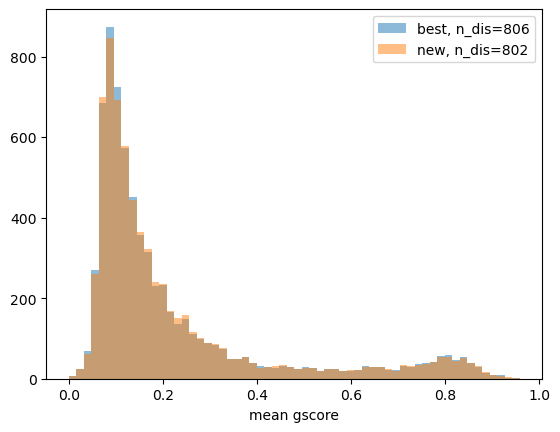

,entity_name,cluster_size,sequence,temperature,pH,ionic_strength,total_bbshifts,mean_gscore,gscores
label,,,,,,,,,
9_1_1_1,carboxypeptidase inhibitor,3,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,308.00,3.82,0.1000,102.0,0.090743,"[nan, 0.2454, 0.3479, 0.3993, 0.3947, 0.2264, ..."
26_1_1_1,glycoprotein D-1,1,MADPNRFRGKDLPVLDQLTDPP,293.00,4.70,0.1000,55.0,0.706490,"[nan, 0.8055, 0.7937, 0.6111, 0.3137, 0.4028, ..."
32_1_1_1,lac repressor headpiece,9,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,291.00,6.85,0.1000,121.0,0.123321,"[nan, nan, 0.1458, 0.0797, 0.0859, 0.0887, 0.1..."
39_1_1_1,metallothionein-2,5,XMDPNCSCATDGSCSCAGSCKCKQCKKTSCKKSCCSCCPVGCAKCS...,298.00,7.00,0.1000,146.0,0.133115,"[nan, 0.3863, 0.406, 0.1919, 0.1133, 0.0301, 0..."
41_1_1_1,neutrophil NP-5,1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,293.00,3.50,0.1000,88.0,0.103945,"[nan, 0.1615, 0.1117, 0.1094, 0.0774, 0.1508, ..."
...,...,...,...,...,...,...,...,...,...
53396_1_1_1,entity_1,1,GSDQSENVDRGAGSIREAGGAFGKREQAEEERYFRAQSREQLAALK...,310.15,5.30,0.2090,523.0,0.331722,"[nan, 0.3723, 0.2999, 0.3817, 0.4018, 0.6082, ..."
53398_1_1_1,entity_1,1,PAGQPERTLESLLAHLQEQHGLRVRILLHGSALLYAAGWSPEKQAQ...,293.15,7.40,0.1000,443.0,0.081394,"[nan, 0.0482, 0.0643, 0.1115, 0.0818, 0.0556, ..."
53400_1_1_1,entity_1,1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,298.00,7.40,0.1617,238.0,0.854909,"[nan, nan, nan, 0.9551, 0.9564, 0.7819, 0.6935..."


In [37]:
df = {}
for tag in ["best", "new"]:
    filename = f"{folder}/{filtering}-dataset_{tag}.csv"
    df[tag] = pd.read_csv(
        filename, index_col="label", converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)}
    )
    plt.hist(df[tag]["mean_gscore"], bins="auto", alpha=0.5, label=f"{tag}, n_dis={sum(df[tag]['mean_gscore'] >= 0.5)}")
plt.xlabel("mean gscore")
plt.legend()
plt.show()
df[tag]